<h1>Table of Contents<span class="tocSkip"></span></h1>
<div class="toc"><ul class="toc-item"><li><span><a href="#Import-libraries" data-toc-modified-id="Import-libraries-1"><span class="toc-item-num">1&nbsp;&nbsp;</span>Import libraries</a></span></li><li><span><a href="#Run-HypoDD" data-toc-modified-id="Run-HypoDD-2"><span class="toc-item-num">2&nbsp;&nbsp;</span>Run <code>HypoDD</code></a></span></li><li><span><a href="#Read-hypoDD.reloc-file" data-toc-modified-id="Read-hypoDD.reloc-file-3"><span class="toc-item-num">3&nbsp;&nbsp;</span>Read <code>hypoDD.reloc</code> file</a></span></li><li><span><a href="#Plot-relocated-epicenters" data-toc-modified-id="Plot-relocated-epicenters-4"><span class="toc-item-num">4&nbsp;&nbsp;</span>Plot relocated epicenters</a></span></li><li><span><a href="#Cartesian-coordinates" data-toc-modified-id="Cartesian-coordinates-5"><span class="toc-item-num">5&nbsp;&nbsp;</span>Cartesian coordinates</a></span></li><li><span><a href="#Depth-histogram" data-toc-modified-id="Depth-histogram-6"><span class="toc-item-num">6&nbsp;&nbsp;</span>Depth histogram</a></span></li></ul></div>

In [2]:
from IPython.core.display import display, HTML 
display(HTML("<style>.container { width:100% !important; }</style>"))

/tmp/ipykernel_139114/343306588.py:1: DeprecationWarning: Importing display from IPython.core.display is deprecated since IPython 7.14, please import from IPython display
  from IPython.core.display import display, HTML


## Import libraries

In [3]:
import numpy as np
import pandas as pd
import pygmt as pmt
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import MultipleLocator
from datetime import datetime
from glob import glob
import os
from datetime import datetime
from numpy.random import choice
from tqdm import tqdm
from matplotlib.patches import Ellipse
import matplotlib.transforms as transforms
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)

%config InlineBackend.print_figure_kwargs={'facecolor' : "w"}

# Font
import matplotlib as mpl
import matplotlib.font_manager as font_manager
font_dir = ['/home/msseo/Download/Helvetica']
for font in font_manager.findSystemFonts(font_dir):
    font_manager.fontManager.addfont(font)

mpl.rcParams['font.family']="helvetica"
mpl.rcParams['axes.unicode_minus']=False

## Run `HypoDD`

In [4]:
# Run HypoDD and arange files
os.system("./hypoDD.sh")

starting hypoDD (v1.3 - 11/2010)...          Fri Oct 17 00:15:07 2025 
INPUT FILES:
cross dtime data:  
catalog dtime data: dt.ct
events: event.dat
stations: station.dat
OUTPUT FILES:
initial locations: hypoDD.loc
relocated events: hypoDD.reloc
event pair residuals: hypoDD.res
station residuals: hypoDD.sta
source parameters:  
 Relocate all clusters
 Relocate all events
Reading data ...   Fri Oct 17 00:15:07 2025 
# events =    12
# stations < maxdist =     59
# catalog P dtimes =     901
# catalog S dtimes =     925
# dtimes total =     1826
# events after dtime match =         12
# stations =     57

no clustering performed.

RELOCATION OF CLUSTER: 1     Fri Oct 17 00:15:07 2025 
----------------------
Initial trial sources =     1

  IT   EV  CT    RMSCT     RST   DX   DY   DZ   DT   OS  AQ
        %   %   ms     %    ms    m    m    m   ms    m 
 1  1 100 100   27 -73.0   183   42   73   84   38    0   0
 2  2 100 100   27  -0.0   183    0    0    1    0    0   0
 3  3 100 100   27

0

  -0.0   183    0    0    0    0    0   0
 4  4 100 100   27   0.0   183    0    0    0    0    0   0
 5  5 100  99   22 -18.6   187    3    5   15    2    0   0
 6  6 100  98   22  -3.8   190    1    2    4    0    0   0
 7  7 100  98   21  -0.7   111    0    0    1    0    0   0
 8  8 100  98   21  -0.0   111    0    0    1    0    1   0
 9  9 100  96   19  -9.1    92    2    3    7    1    1   0
10 10 100  96   19  -2.1    89    1    1    2    0    1   0
11 11 100  96   19  -0.6    89    0    0    1    0    1   0
12 12 100  95   19  -0.3    89    0    0    1    3    2   0
13 13 100  94   17  -7.1    77    2    2    4    0    2   0
14 14 100  93   17  -2.6    73    1    1    2    0    2   0
15 15 100  93   17  -0.9    73    0    0    1    0    3   0
16 16 100  93   17  -0.3    73    0    0    0    1    3   0
17 17 100  85   13 -23.3    56    4    4    9    1    3   0
18 18 100  83   11 -13.0    55    3    4    9    1    3   0
19 19 100  81   10  -8.6    46    2    3    7    1    3   

## Read `hypoDD.reloc` file

In [5]:
# Change hypoDD.reloc file into *csv format so that it can be read into DataFrame object
f1=open("hypoDD.reloc", 'r')
# f2=open("hypoDD.reloc.lsqr.csv", 'w')
f2=open("hypoDD.reloc.svd.csv", 'w')
lines=f1.readlines()
f2.write("ID,LAT,LON,DEPTH,X,Y,Z,EX,EY,EZ,YR,MO,DY,HR,MI,SC,MAG,NCCP,NCCS,NCTP,NCTS,RCC,RCT,CID\n")
for line in lines:
    csv_line_list=[]
    csv_line_list.append(line[0:9].replace(" ", ""))
    csv_line_list.append(line[9:20].replace(" ", ""))
    csv_line_list.append(line[20:32].replace(" ", ""))
    csv_line_list.append(line[32:42].replace(" ", ""))
    csv_line_list.append(line[42:53].replace(" ", ""))
    csv_line_list.append(line[53:64].replace(" ", ""))
    csv_line_list.append(line[64:75].replace(" ", ""))
    csv_line_list.append(line[75:84].replace(" ", ""))
    csv_line_list.append(line[84:93].replace(" ", ""))
    csv_line_list.append(line[93:102].replace(" ", ""))
    csv_line_list.append(line[102:107].replace(" ", ""))
    csv_line_list.append(line[107:110].replace(" ", ""))
    csv_line_list.append(line[110:113].replace(" ", ""))
    csv_line_list.append(line[113:116].replace(" ", ""))
    csv_line_list.append(line[116:119].replace(" ", ""))
    csv_line_list.append(line[119:126].replace(" ", ""))
    csv_line_list.append(line[126:131].replace(" ", ""))
    csv_line_list.append(line[131:137].replace(" ", ""))
    csv_line_list.append(line[137:143].replace(" ", ""))
    csv_line_list.append(line[143:149].replace(" ", ""))
    csv_line_list.append(line[149:155].replace(" ", ""))
    csv_line_list.append(line[155:162].replace(" ", ""))
    csv_line_list.append(line[162:169].replace(" ", ""))
    csv_line_list.append(line[169:173].replace(" ", ""))
    csv_line=",".join(csv_line_list)
    f2.write(csv_line+"\n")
f2.close()
f1.close()

In [6]:
path_to_dir="/home/msseo/works/19.Korea_Directivity/49.251008_Okcheon/2.HypoDD/01.dt.ct/"
svd_filename="hypoDD.reloc.svd.csv"
svd_relocated_catalog=pd.read_csv(path_to_dir+svd_filename, sep=",")
# lsqr_filename="hypoDD.reloc.lsqr.csv"
# lsqr_relocated_catalog=pd.read_csv(path_to_dir+lsqr_filename, sep=",")
# CID_list=[1, 2, 3, 4]
# relocated_catalog=relocated_catalog[relocated_catalog["CID"].isin(CID_list)].reset_index(drop=True)
svd_relocated_catalog

,ID,LAT,LON,DEPTH,X,Y,Z,EX,EY,EZ,...,MI,SC,MAG,NCCP,NCCS,NCTP,NCTS,RCC,RCT,CID
0,200000,36.283065,127.759928,8.579,1.4,-83.3,16.1,2.4,3.3,8.3,...,32,41.17,0.0,0,0,98,67,-9.0,0.006,1
1,200001,36.283150,127.760213,8.749,27.4,-73.8,185.9,2.9,4.0,8.8,...,28,11.72,0.0,0,0,106,79,-9.0,0.006,1
2,200002,36.283114,127.759912,8.578,0.0,-78.0,14.9,2.8,3.7,8.4,...,52,50.28,0.0,0,0,83,51,-9.0,0.006,1
3,200003,36.283110,127.759928,8.585,1.5,-78.5,21.4,2.6,3.5,7.9,...,22,8.66,0.0,0,0,122,61,-9.0,0.006,1
4,200004,36.283781,127.760360,8.571,39.9,-4.2,7.2,2.6,3.4,7.8,...,17,15.18,0.0,0,0,108,68,-9.0,0.006,1
5,200005,36.283403,127.759578,8.600,-30.2,-46.3,37.1,2.6,3.5,8.0,...,49,39.59,0.0,0,0,115,70,-9.0,0.006,1
6,200006,36.283419,127.759546,8.559,-32.7,-44.1,-4.5,3.0,3.9,9.9,...,55,41.35,0.0,0,0,51,27,-9.0,0.005,1
7,200007,36.284534,127.758162,8.426,-157.4,79.3,-137.2,4.5,6.0,14.7,...,8,19.73,0.0,0,0,44,25,-9.0,0.005,1
8,200008,36.286511,127.758936,8.538,-87.4,298.8,-25.7,8.9,11.7,28.8,...,14,32.86,0.0,0,0,44,10,-9.0,0.003,1
9,200009,36.285099,127.762036,8.483,191.1,142.1,-80.4,5.2,6.8,15.0,...,16,5.91,0.0,0,0,62,17,-9.0,0.004,1


In [7]:
kma_catalog=pd.read_csv("/home/msseo/works/19.Korea_Directivity/49.251008_Okcheon/event_catalog/okcheon_catalog.csv", sep=',')
mag_list=np.array(kma_catalog["Magnitude"])

In [8]:
len(mag_list)

12

## Plot relocated epicenters

In [9]:
# Reference: https://forum.generic-mapping-tools.org/t/pygmt-plot-errorbars/1354/5

# 1) SVD relocation data
svd_df=pd.DataFrame(
    data={
        "x": svd_relocated_catalog["LON"],
        "y": svd_relocated_catalog["LAT"],
        "x-error": svd_relocated_catalog["EX"]*0.000009009,
        "y-error": svd_relocated_catalog["EY"]*0.000009009
    }
)

# # 2) LSQR relocation data
# lsqr_df=pd.DataFrame(
#     data={
#         "x": lsqr_relocated_catalog["LON"],
#         "y": lsqr_relocated_catalog["LAT"],
#         "x-error": lsqr_relocated_catalog["EX"]*0.000009009,
#         "y-error": lsqr_relocated_catalog["EY"]*0.000009009
#     }
# )

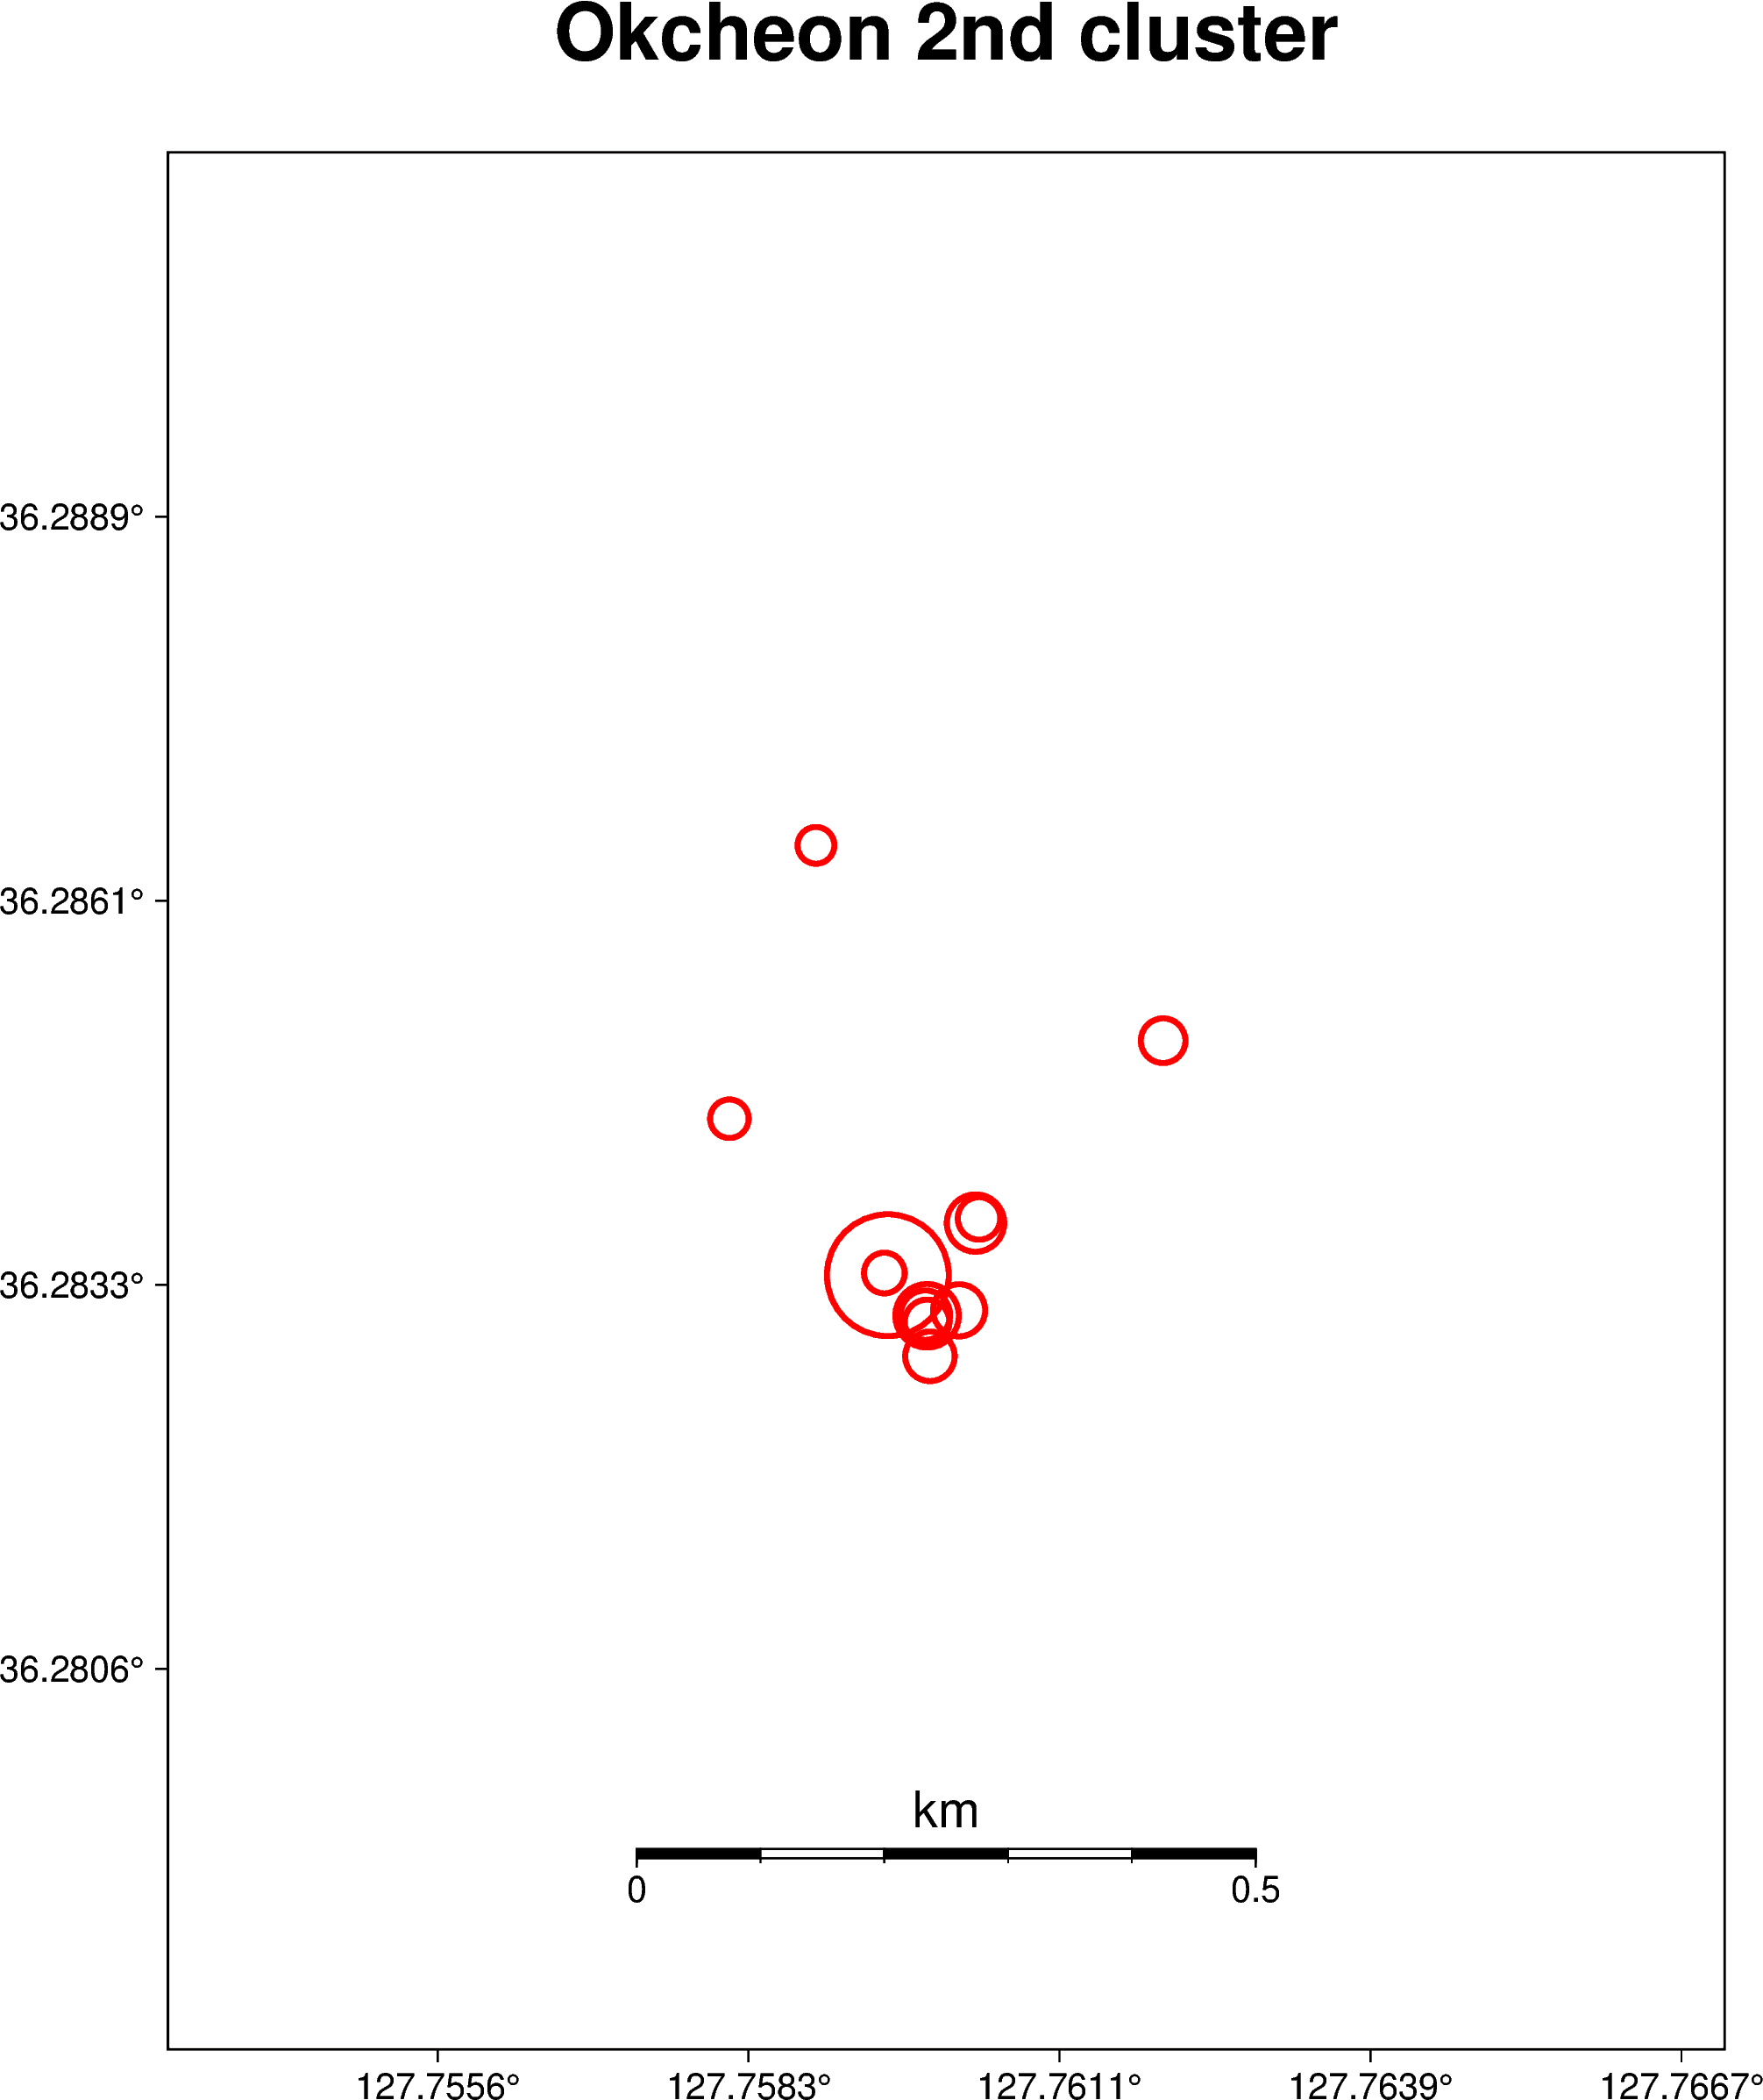

In [13]:
################ Draw epicenter locations with fault traces and stations ################
fig=pmt.Figure()
pmt.config(FORMAT_GEO_MAP="ddd.xxxx", MAP_FRAME_TYPE="plain") # Use decimal degrees for latitude/longitude

#######################################################################################################
# 1) Set the region for the plot to be slightly larger than the data bounds
region=[svd_relocated_catalog["LON"].min()-0.005,
        svd_relocated_catalog["LON"].max()+0.005,
        svd_relocated_catalog["LAT"].min()-0.005,
        svd_relocated_catalog["LAT"].max()+0.005
        ]

fig.basemap(region=region, projection="M15c", frame=["a", '+t"Okcheon 2nd cluster"'])
fig.coast(land="white", water="#fff0dc", shorelines=True, map_scale="n0.5/0.1+f+l+c126.72/35.70+w0.5")

#######################################################################################################
# 2) Plot newly located epicenters 

# Plot epicenters
for i in range(len(svd_relocated_catalog)):
    csize=0.25*np.exp(0.5*mag_list[i])
    # csize=0.5
    fig.plot(x=svd_relocated_catalog["LON"][i], y=svd_relocated_catalog["LAT"][i], style=f"c{csize}c", pen="1.5p,red")

fig.show(width=500)
# fig.savefig(dpi=300, fname="Figure/200811_cluster_10km_epicenter_map_dt_cc.png", show=False)

## Cartesian coordinates

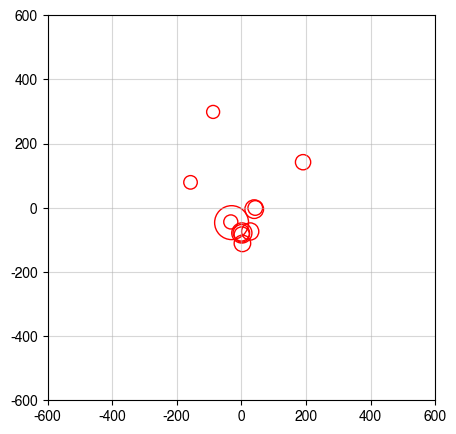

In [15]:
plt.figure(figsize=(5, 5))
plt.scatter(svd_relocated_catalog["X"]-np.mean(svd_relocated_catalog["X"]), svd_relocated_catalog["Y"]-np.mean(svd_relocated_catalog["Y"]), color="r", s=50*np.exp(0.8*mag_list), facecolors="none")
plt.xlim(-600, 600)
plt.ylim(-600, 600)
plt.grid(True, alpha=0.5)
plt.show();

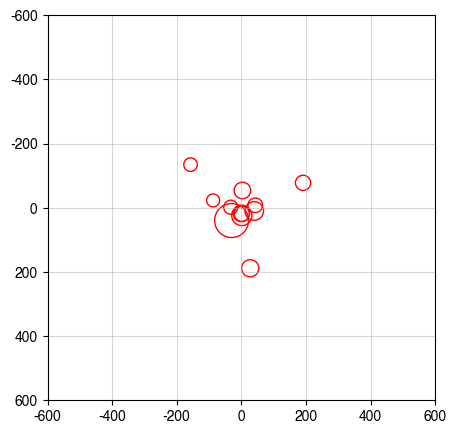

In [16]:
plt.figure(figsize=(5, 5))
plt.scatter(svd_relocated_catalog["X"]-np.mean(svd_relocated_catalog["X"]), svd_relocated_catalog["Z"]-np.mean(svd_relocated_catalog["Z"]), color="r", s=50*np.exp(0.8*mag_list), facecolors="none")
plt.xlim(-600, 600)
plt.ylim(600, -600)
plt.grid(True, alpha=0.5)
plt.show();

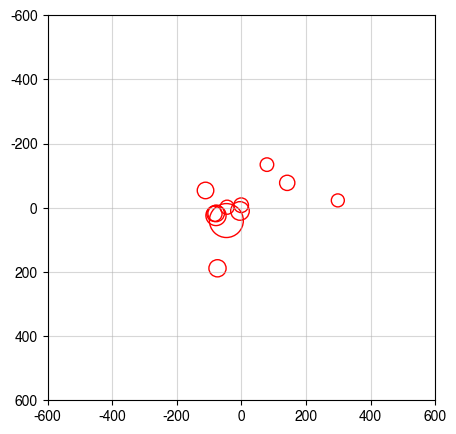

In [17]:
plt.figure(figsize=(5, 5))
plt.scatter(svd_relocated_catalog["Y"]-np.mean(svd_relocated_catalog["Y"]), svd_relocated_catalog["Z"]-np.mean(svd_relocated_catalog["Z"]), color="r", s=50*np.exp(0.8*mag_list), facecolors="none")
plt.xlim(-600, 600)
plt.ylim(600, -600)
plt.grid(True, alpha=0.5)
plt.show();

## Depth histogram

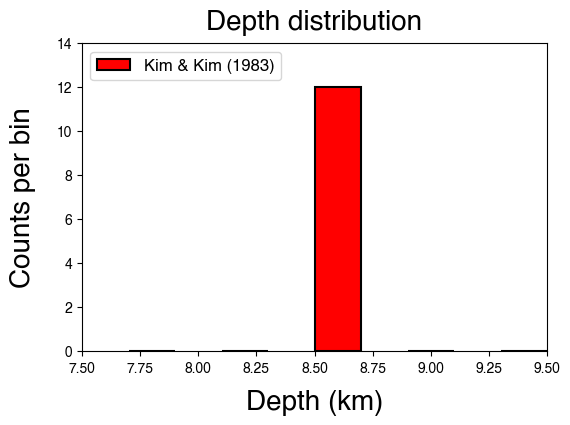

In [26]:
data=svd_relocated_catalog["DEPTH"]
plt.figure(figsize=(6, 4))
plt.hist(data, bins=50, rwidth=0.5, color="r", edgecolor="k", lw=1.5, range=(0, 20), label="Kim & Kim (1983)")
plt.title("Depth distribution", fontsize=20, pad=10)
plt.xlabel("Depth (km)", fontsize=20, labelpad=10)
plt.ylabel("Counts per bin", fontsize=20, labelpad=15)
# plt.xticks(np.arange(0, 18, 2), fontsize=18)
# plt.yticks(np.arange(0, 18, 2), fontsize=18)
# plt.xticks(np.arange(0, 22, 2), fontsize=15)
# plt.yticks(np.arange(0, 55, 5), fontsize=15)
plt.legend(prop={"size": 12}, loc="upper left")
plt.xlim(7.5, 9.5)
plt.ylim(0, 14)
# plt.ylim(7, 9)
plt.show()
# plt.savefig("Figure/dt_cc_depth_distribution.png", dpi=300)